In [2]:
# ========== Standard Library & Data Handling Imports ==========
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import pickle
import os

# ========== Scikit-learn & ML Tools ==========
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
# Load the datasets
payments_path = 'synthetic_sme_payments.csv'
cash_flow_path = 'synthetic_sme_daily_cash_flow.csv'
expenses_path = 'synthetic_sme_expenses.csv'
invoices_path = 'synthetic_sme_invoices.csv'

df_payments = pd.read_csv(payments_path)
df_cash_flow = pd.read_csv(cash_flow_path)
df_expenses = pd.read_csv(expenses_path)
df_invoices = pd.read_csv(invoices_path)

df = df_payments
df1 = df_cash_flow
df2 = df_expenses
df3 = df_invoices


In [4]:
# Display preview of df1 (Daily Cash Flow)
print("Daily Cash Flow (df1) Preview:")
df1.head()


Daily Cash Flow (df1) Preview:


,date,business_id,sector,day_of_week,month,is_weekend,sales_egp,cash_sales_egp,receivables_created_egp,receivables_collected_egp,...,payroll_egp,rent_egp,taxes_egp,loan_payments_egp,other_income_egp,total_cash_inflow_egp,total_cash_outflow_egp,net_cash_flow_egp,closing_cash_balance_egp,promotion_flag
0,2023-01-01,SME_001,Wholesale,6,1,1,12682.52,6395.56,3622.22,0.0,...,0.0,22224.47,0.0,0.0,0.00,6395.56,24700.35,-18304.79,191695.21,0
1,2023-01-02,SME_001,Wholesale,0,1,0,12049.91,6581.06,7015.34,0.0,...,0.0,0.00,0.0,0.0,0.00,6581.06,2155.21,4425.85,196121.06,0
2,2023-01-03,SME_001,Wholesale,1,1,0,18187.42,8906.32,10360.79,0.0,...,0.0,0.00,0.0,0.0,0.00,8906.32,4944.96,3961.36,200082.42,0
3,2023-01-04,SME_001,Wholesale,2,1,0,18822.29,7744.51,9255.20,0.0,...,0.0,0.00,0.0,0.0,20659.64,28404.15,2904.72,25499.43,225581.85,0
4,2023-01-05,SME_001,Wholesale,3,1,0,8892.64,4157.31,3950.01,0.0,...,0.0,0.00,0.0,0.0,0.00,4157.31,4615.34,-458.03,225123.82,0


In [5]:
# Summary statistics of df1
df1.describe().T


,count,mean,std,min,25%,50%,75%,max
day_of_week,8768.0,2.997263e+00,2.001708,0.00,1.0000,3.000,5.000000e+00,6.00
month,8768.0,6.521898e+00,3.449183,1.00,4.0000,7.000,1.000000e+01,12.00
is_weekend,8768.0,2.855839e-01,0.451718,0.00,0.0000,0.000,1.000000e+00,1.00
sales_egp,8768.0,1.085744e+04,5050.295729,1387.91,7114.1350,9688.445,1.369869e+04,36385.22
cash_sales_egp,8768.0,6.684072e+03,3029.775792,827.36,4372.3625,6338.335,8.463157e+03,23740.77
receivables_created_egp,8768.0,4.153220e+03,2827.664175,306.92,2094.8400,3239.795,5.583852e+03,21590.77
receivables_collected_egp,8768.0,3.829353e+03,4827.902414,0.00,0.0000,2449.850,5.542163e+03,51033.47
supplier_payables_created_egp,8768.0,5.559935e+03,2442.957958,748.10,3716.5050,4994.165,6.899465e+03,18503.15
supplier_payments_egp,8768.0,5.308947e+03,5324.233341,0.00,0.0000,4475.340,7.849448e+03,40245.89
payroll_egp,8768.0,1.933352e+03,6352.835530,0.00,0.0000,0.000,0.000000e+00,41819.25


In [6]:
# Dataset shape
print("df1 Shape:", df1.shape)


df1 Shape: (8768, 22)


In [7]:
# Value counts of sector
df1['sector'].value_counts()


sector
Wholesale       2192
Retail          2192
Services        2192
Distribution    1096
Ecommerce       1096
Name: count, dtype: int64

In [8]:
# Check for missing values
df1.isnull().sum()


date                             0
business_id                      0
sector                           0
day_of_week                      0
month                            0
is_weekend                       0
sales_egp                        0
cash_sales_egp                   0
receivables_created_egp          0
receivables_collected_egp        0
supplier_payables_created_egp    0
supplier_payments_egp            0
payroll_egp                      0
rent_egp                         0
taxes_egp                        0
loan_payments_egp                0
other_income_egp                 0
total_cash_inflow_egp            0
total_cash_outflow_egp           0
net_cash_flow_egp                0
closing_cash_balance_egp         0
promotion_flag                   0
dtype: int64

In [9]:
# Check for duplicates
df1.duplicated().sum()


np.int64(0)

In [10]:
# Summary of target: net_cash_flow_egp
df1['net_cash_flow_egp'].describe()


count     8768.000000
mean      2094.867000
std      10910.415234
min     -68971.220000
25%      -2843.975000
50%       2508.555000
75%       7726.172500
max      50931.800000
Name: net_cash_flow_egp, dtype: float64

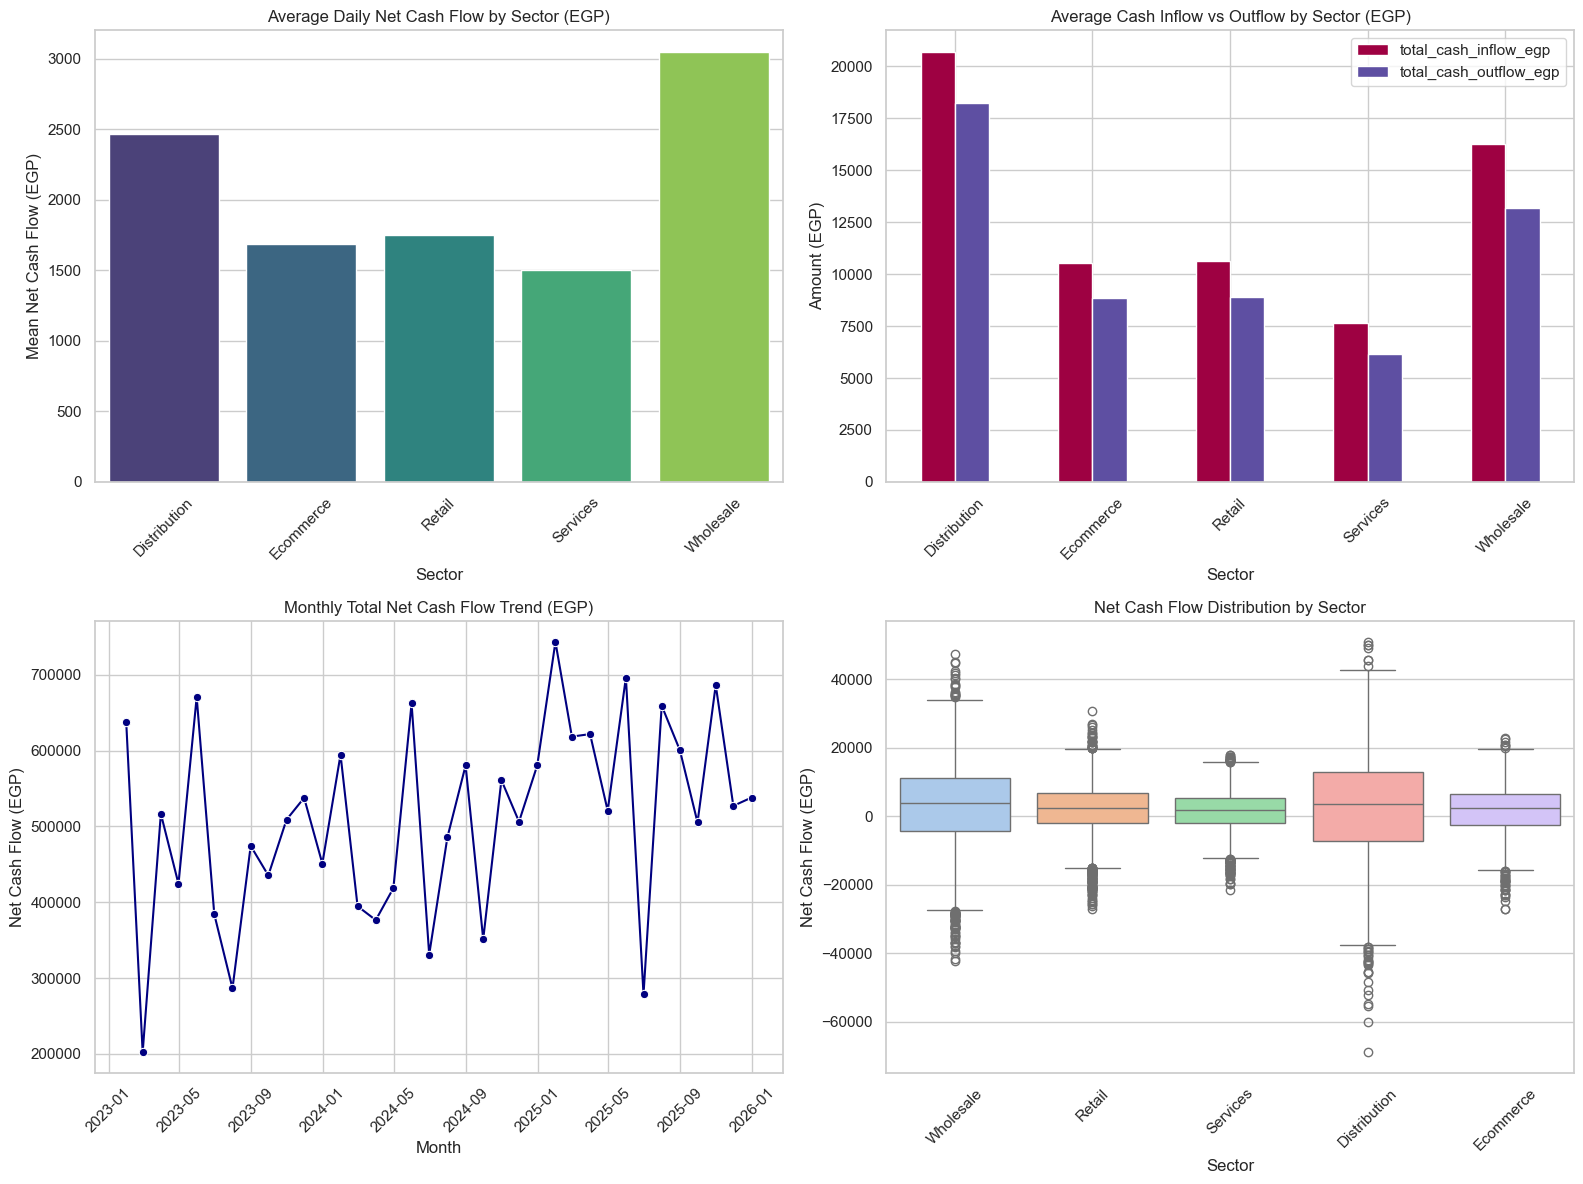

In [11]:
# ========== Visualizations for df1 (Daily Cash Flow) ==========
df1_viz = df1.copy()
df1_viz['date'] = pd.to_datetime(df1_viz['date'])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Net Cash Flow by Sector
sns.barplot(
    ax=axes[0, 0],
    x=df1_viz.groupby('sector')['net_cash_flow_egp'].mean().index,
    y=df1_viz.groupby('sector')['net_cash_flow_egp'].mean().values,
    palette='viridis'
)
axes[0, 0].set_title('Average Daily Net Cash Flow by Sector (EGP)')
axes[0, 0].set_xlabel('Sector')
axes[0, 0].set_ylabel('Mean Net Cash Flow (EGP)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Total Inflow vs Outflow by Sector
inflow_outflow = df1_viz.groupby('sector')[['total_cash_inflow_egp', 'total_cash_outflow_egp']].mean()
inflow_outflow.plot(kind='bar', ax=axes[0, 1], colormap='Spectral')
axes[0, 1].set_title('Average Cash Inflow vs Outflow by Sector (EGP)')
axes[0, 1].set_xlabel('Sector')
axes[0, 1].set_ylabel('Amount (EGP)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Monthly Net Cash Flow Trend
df1_monthly = df1_viz.set_index('date').resample('ME')['net_cash_flow_egp'].sum().reset_index()
sns.lineplot(
    ax=axes[1, 0],
    data=df1_monthly,
    x='date',
    y='net_cash_flow_egp',
    marker='o',
    color='navy'
)
axes[1, 0].set_title('Monthly Total Net Cash Flow Trend (EGP)')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Net Cash Flow (EGP)')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Boxplot of Net Cash Flow by Sector
sns.boxplot(
    ax=axes[1, 1],
    data=df1_viz,
    x='sector',
    y='net_cash_flow_egp',
    palette='pastel'
)
axes[1, 1].set_title('Net Cash Flow Distribution by Sector')
axes[1, 1].set_xlabel('Sector')
axes[1, 1].set_ylabel('Net Cash Flow (EGP)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [12]:
# ========== Preprocessing & Feature Engineering ==========
df1_encoded = df1.copy()

# Date feature extraction
df1_encoded['date'] = pd.to_datetime(df1_encoded['date'])
df1_encoded['year'] = df1_encoded['date'].dt.year
df1_encoded['day'] = df1_encoded['date'].dt.day

# Drop non-feature / target leakage columns (strict mode)
leaky_cols = ['date', 'closing_cash_balance_egp', 'total_cash_inflow_egp', 'total_cash_outflow_egp']
df1_encoded.drop(columns=leaky_cols, inplace=True)

# Encode categorical variables
le_bus = LabelEncoder()
df1_encoded['business_id'] = le_bus.fit_transform(df1_encoded['business_id'])

le_sec = LabelEncoder()
df1_encoded['sector'] = le_sec.fit_transform(df1_encoded['sector'])

print("Encoded df1 preview:")
df1_encoded.head()


Encoded df1 preview:


,business_id,sector,day_of_week,month,is_weekend,sales_egp,cash_sales_egp,receivables_created_egp,receivables_collected_egp,supplier_payables_created_egp,supplier_payments_egp,payroll_egp,rent_egp,taxes_egp,loan_payments_egp,other_income_egp,net_cash_flow_egp,promotion_flag,year,day
0,0,4,6,1,1,12682.52,6395.56,3622.22,0.0,8424.36,0.0,0.0,22224.47,0.0,0.0,0.00,-18304.79,0,2023,1
1,0,4,0,1,0,12049.91,6581.06,7015.34,0.0,7915.83,0.0,0.0,0.00,0.0,0.0,0.00,4425.85,0,2023,2
2,0,4,1,1,0,18187.42,8906.32,10360.79,0.0,7946.67,0.0,0.0,0.00,0.0,0.0,0.00,3961.36,0,2023,3
3,0,4,2,1,0,18822.29,7744.51,9255.20,0.0,7905.62,0.0,0.0,0.00,0.0,0.0,20659.64,25499.43,0,2023,4
4,0,4,3,1,0,8892.64,4157.31,3950.01,0.0,8146.69,0.0,0.0,0.00,0.0,0.0,0.00,-458.03,0,2023,5


In [13]:
# Separate Features (X) and Target (y: net_cash_flow_egp)
X = df1_encoded.drop('net_cash_flow_egp', axis=1)
y = df1_encoded['net_cash_flow_egp']

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


X_train shape: (7014, 19), X_test shape: (1754, 19)


In [14]:
# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

print("Data Scaling Complete!")
X_train_scaled_df.head()


Data Scaling Complete!


,business_id,sector,day_of_week,month,is_weekend,sales_egp,cash_sales_egp,receivables_created_egp,receivables_collected_egp,supplier_payables_created_egp,supplier_payments_egp,payroll_egp,rent_egp,taxes_egp,loan_payments_egp,other_income_egp,promotion_flag,year,day
0,0.656571,1.238434,1.005633,0.714026,1.592257,0.110300,-0.653537,-0.286090,4.163076,0.054949,0.168250,-0.307649,-0.168966,-0.10014,-0.168635,-0.429406,-0.218283,-0.003327,0.602178
1,1.093994,0.478670,-0.491610,0.423848,-0.628039,-0.967828,-1.342832,-0.375431,-0.300187,-1.082002,-0.423560,-0.307649,-0.168966,-0.10014,-0.168635,-0.429406,-0.218283,-1.231365,0.033425
2,1.093994,0.478670,0.007471,-1.317218,-0.628039,-0.967714,-1.078226,-0.230864,-0.793443,-0.335366,-0.373866,-0.307649,-0.168966,-0.10014,-0.168635,-0.429406,-0.218283,-1.231365,0.033425
3,0.219148,-1.040856,-0.990691,-0.156507,-0.628039,-0.162596,0.021852,-0.492234,-0.139128,-0.691077,-0.069247,-0.307649,-0.168966,-0.10014,-0.168635,-0.429406,-0.218283,-1.231365,0.488427
4,0.656571,1.238434,1.504714,-0.156507,1.592257,-0.015725,-0.616273,0.306733,-0.793443,0.355374,0.344552,-0.307649,-0.168966,-0.10014,-0.168635,-0.429406,-0.218283,-1.231365,-1.331583


In [15]:
# ========== Model Training & Evaluation ==========
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42, n_estimators=100),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'XGBoost Regressor': XGBRegressor(random_state=42)
}

results = {}
print("=== Training Regression Models on Daily Cash Flow ===\n")

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results[name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

results_df = pd.DataFrame(results).T
print("\n=== Model Comparison Results ===")
display(results_df.sort_values(by='R2 Score', ascending=False))


=== Training Regression Models on Daily Cash Flow ===

Training Linear Regression...
Training Decision Tree Regressor...
Training Random Forest Regressor...
Training Gradient Boosting Regressor...
Training XGBoost Regressor...

=== Model Comparison Results ===


,MAE,MSE,RMSE,R2 Score
Linear Regression,503.056537,4.172710e+05,645.965188,0.996234
Gradient Boosting Regressor,1070.872254,2.117299e+06,1455.094205,0.980890
XGBoost Regressor,969.421233,2.124023e+06,1457.402743,0.980830
Random Forest Regressor,1143.866534,3.487256e+06,1867.419485,0.968526
Decision Tree Regressor,1924.143261,1.106989e+07,3327.144487,0.900088


In [16]:
# ========== Hyperparameter Fine-Tuning ==========
print("=== Hyperparameter Fine-tuning Random Forest ===\n")

rf_param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_grid = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=rf_param_dist,
    n_iter=5,
    scoring='r2',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=1
)
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
rf_predictions = best_rf.predict(X_test_scaled)
print(f"Best RF Params: {rf_grid.best_params_}")
print(f"Fine-tuned RF R2 Score: {r2_score(y_test, rf_predictions):.4f}")


=== Hyperparameter Fine-tuning Random Forest ===

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best RF Params: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': None}
Fine-tuned RF R2 Score: 0.9685


In [17]:
# ========== Save Model and Scaler ==========
with open('best_cash_model.pkl', 'wb') as f:
    pickle.dump(best_rf, f)

with open('scaler_cash.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('le_cash_bus.pkl', 'wb') as f:
    pickle.dump(le_bus, f)

with open('le_cash_sec.pkl', 'wb') as f:
    pickle.dump(le_sec, f)

print("Saved 'best_cash_model.pkl', 'scaler_cash.pkl', and label encoders successfully!")


Saved 'best_cash_model.pkl', 'scaler_cash.pkl', and label encoders successfully!


### طريقة تشغيل الـ FastAPI والتجربة
في الخلية التالية يتم كتابة وتشغيل خادم الـ API لتوقع صافي التدفق النقدي `net_cash_flow_egp`:


In [18]:
# Test Sample Prediction
sample_input = X_test.iloc[0:1]
scaled_sample = scaler.transform(sample_input)
pred_cash = best_rf.predict(scaled_sample)[0]
print(f"Actual Cash Flow: {y_test.iloc[0]:.2f} EGP")
print(f"Predicted Cash Flow: {pred_cash:.2f} EGP")


Actual Cash Flow: -2273.92 EGP
Predicted Cash Flow: -2193.42 EGP
